In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from google.colab import files
from google.colab.patches import cv2_imshow

In [2]:
os.makedirs('videos', exist_ok=True)

uploaded = files.upload()

for filename in uploaded.keys():
  dest = os.path.join('videos', filename)
  os.rename(filename, dest)
  print(f'Uploaded File "{filename}" To "{dest}"')

print("\nContents Of Videos Folder:")
print(os.listdir('videos'))

Saving vtest.avi to vtest.avi
Uploaded File "vtest.avi" To "videos/vtest.avi"

Contents Of Videos Folder:
['vtest.avi']


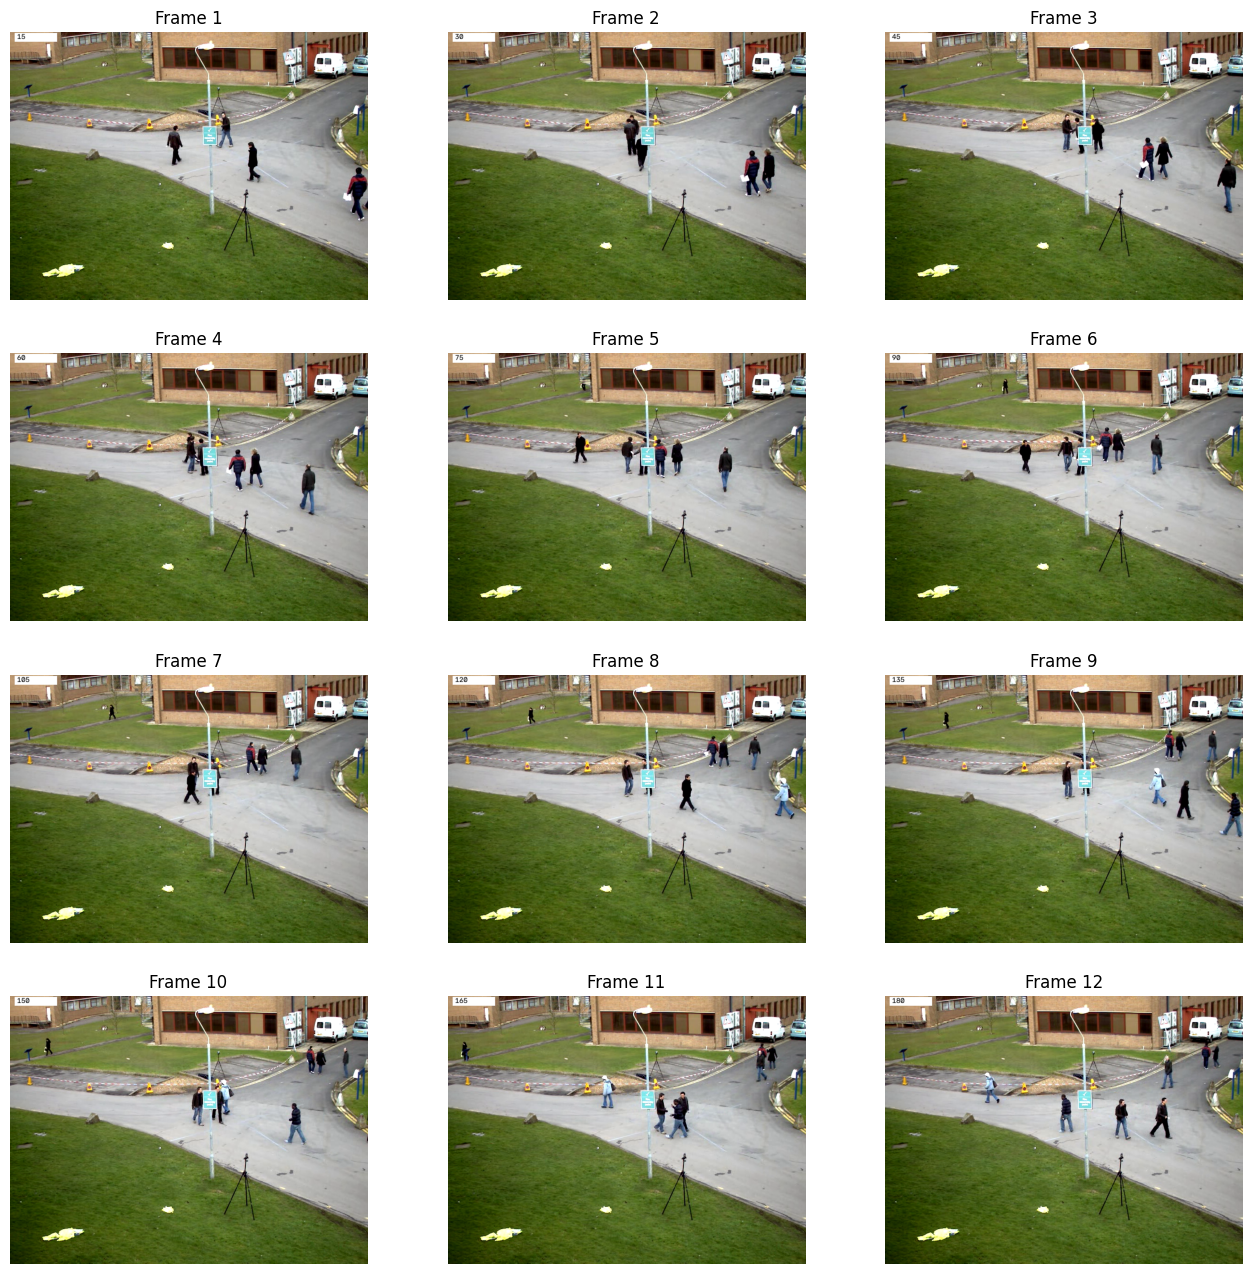

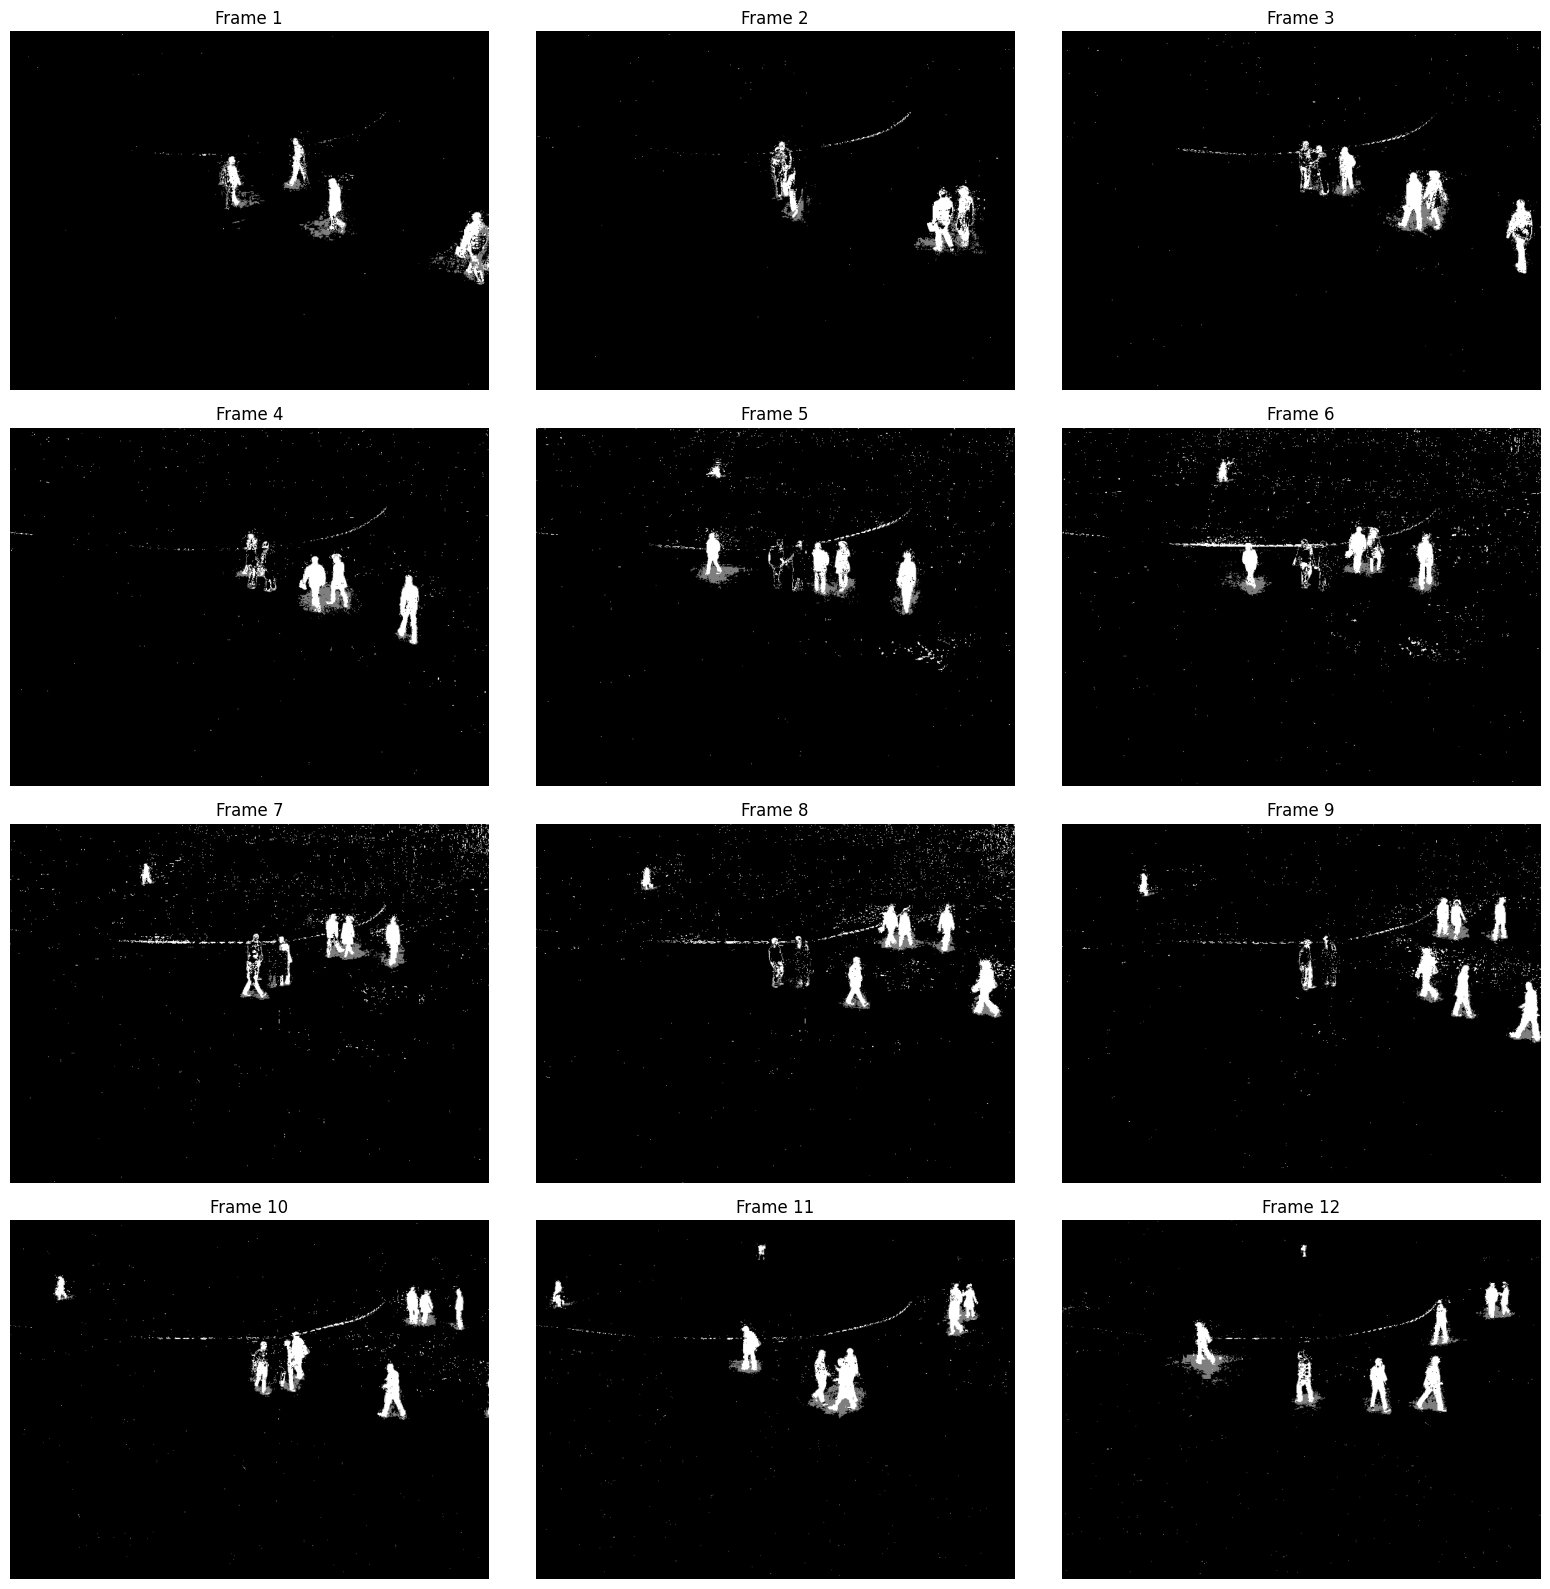

In [4]:
backsub = cv2.createBackgroundSubtractorMOG2()

video_files = [f for f in os.listdir('videos') if f.lower().endswith(('.avi', '.mp4', '.mov', '.mkv'))]
if not video_files:
  raise ValueError("No Video Files Found")

video_path = os.path.join('videos', video_files[0])
cap = cv2.VideoCapture(video_path)

frame_to_show = []
mask_to_show = []
max_frames = 12
frame_idx = 0

while True:
  ret, frame = cap.read()
  if not ret:
    break

  fgMask = backsub.apply(frame)

  cv2.rectangle(frame, (10, 2), (100, 20), (255, 255, 255), -1)
  cv2.putText(frame, str(int(cap.get(cv2.CAP_PROP_POS_FRAMES))),
              (15, 15), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0))

  frame_idx += 1

  if frame_idx % 15 == 0 and len(frame_to_show) < max_frames:
    frame_to_show.append(frame.copy())
    mask_to_show.append(fgMask.copy())

cap.release()

n = len(frame_to_show)

plt.figure(figsize=(16, 4 * ((n + 2) // 3)))

for i in range(n):
  plt.subplot((n + 2) // 3, 3, i + 1)
  plt.imshow(frame_to_show[i][..., ::-1])
  plt.title(f'Frame {i + 1}')
  plt.axis('off')

plt.figure(figsize=(16, 4 * ((n + 2) // 3)))

for i in range(n):
  plt.subplot((n + 2) // 3, 3, i + 1)
  plt.imshow(mask_to_show[i], cmap='gray')
  plt.title(f'Frame {i + 1}')
  plt.axis('off')

plt.tight_layout()
plt.show()

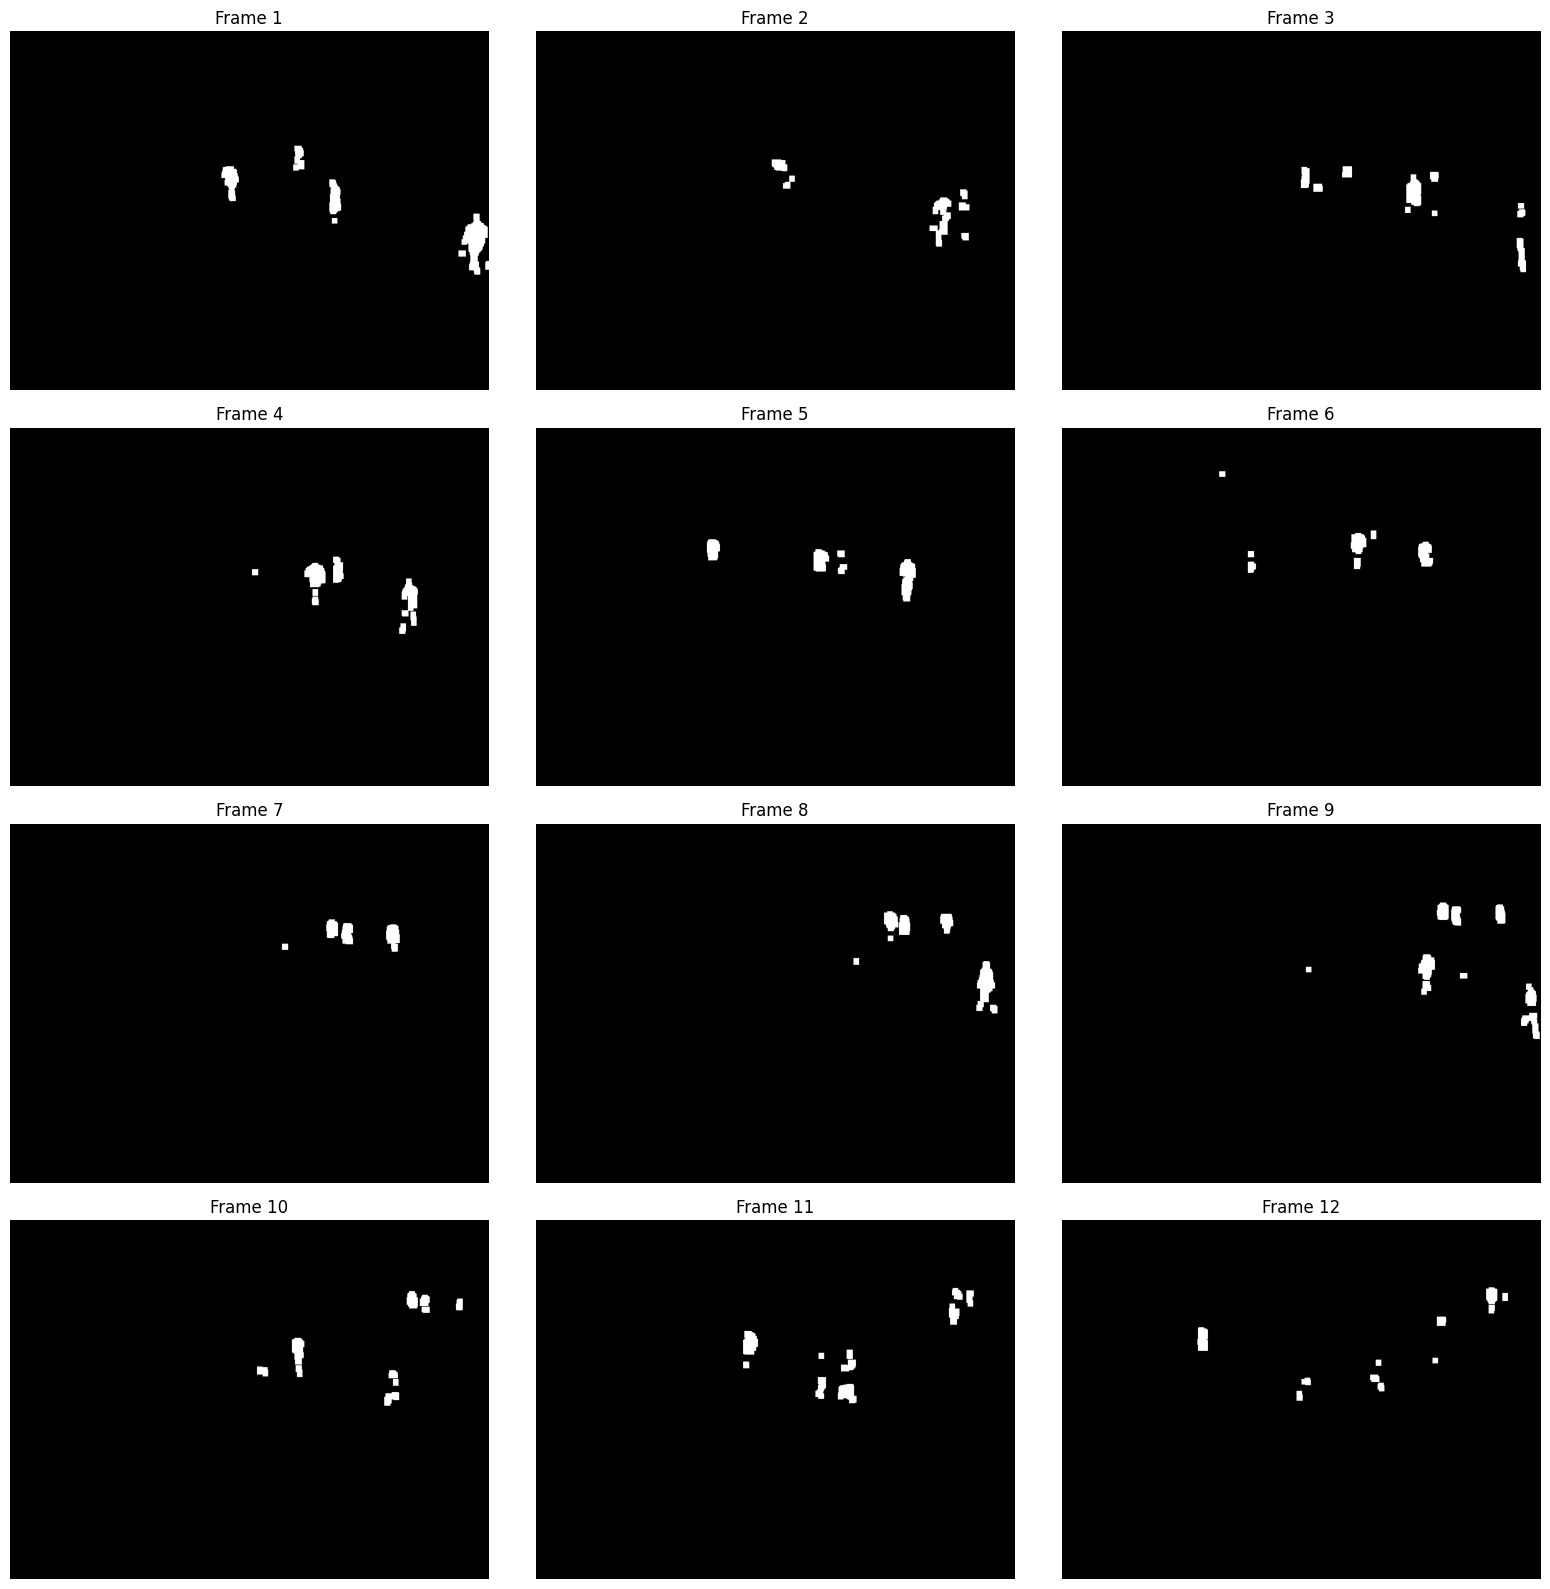

In [5]:
backsub = cv2.createBackgroundSubtractorKNN()

capture = cv2.VideoCapture(video_path)

frame_to_show = []
mask_to_show = []
max_frames = 12
frame_idx = 0

while True:
  ret, frame = capture.read()
  if not ret:
    break

  fgMask = backsub.apply(frame)

  kernel = np.ones((5, 5), np.uint8)
  fgMask = cv2.erode(fgMask, kernel, iterations=2)
  fgMask = cv2.dilate(fgMask, kernel, iterations=2)
  fgMask[np.abs(fgMask) < 255] = 0

  cv2.rectangle(frame, (10, 2), (100, 20), (255, 255, 25), -1)
  cv2.putText(frame, str(int(capture.get(cv2.CAP_PROP_POS_FRAMES))),
              (15, 15), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0))

  frame_idx += 1

  if frame_idx % 15 == 0 and len(frame_to_show) < max_frames:
    frame_to_show.append(frame.copy())
    mask_to_show.append(fgMask.copy())

capture.release()

n = len(frame_to_show)

plt.figure(figsize=(16, 4 * ((n + 2) // 3)))

for i in range(n):
  plt.subplot((n + 2) // 3, 3, i + 1)
  plt.imshow(mask_to_show[i], cmap='gray')
  plt.title(f'Frame {i + 1}')
  plt.axis('off')

plt.tight_layout()
plt.show()